In [9]:
import sys, os
sys.path.insert(0, os.getcwd())
import pathlib

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   evaluate_training, plot_training_log, _train_step)
from task import generate_trials

In [ ]:
# ── Tasks to train on simultaneously ─────────────────────────────────────────
# At each step one task is sampled uniformly at random.
train_tasks = ['pure', 'harmonic']

# Frequency grid context (determines shared input dimensionality).
task_list   = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps        = 20000   # more steps: harder multi-task objective
k              = 200     # snapshot (and print) every k steps
snapshot_every = 2000    # also save checkpoint_{step}.pkl every this many steps
seed           = 0
eval_with_noise = True

# ── Load existing checkpoint instead of re-training ──────────────────────────
load_pre_trained = False   # set True to skip training and load from save_dir

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir    = str(RESULTS_DIR)

In [ ]:
task_label = '-'.join(train_tasks)   # e.g. 'pure-harmonic'
state, cfg = setup_training(task_label, task_list, n_steps, k, seed, save_dir)

In [12]:
# ── Multi-task training setup ─────────────────────────────────────────────────
t_hp       = cfg['t_hp']
save_path  = cfg['save_path']
stim_on    = cfg['stim_on']
stim_off   = cfg['stim_off']
dt         = cfg['dt']
timing     = cfg['timing']
pulse_steps = cfg['pulse_steps']
resp_onset = stim_on + timing.get('resp_onset_pulses', 2) * pulse_steps

rng = np.random.default_rng(seed)
key = jax.random.PRNGKey(seed + 1)
snapshots = []

In [ ]:
if load_pre_trained:
    ckpt_files = sorted(save_path.glob('checkpoint_*.pkl'),
                        key=lambda p: int(p.stem.split('_')[-1]))
    if not ckpt_files:
        fallback = save_path / 'checkpoint.pkl'
        if fallback.exists():
            ckpt_files = [fallback]
        else:
            print(f'No checkpoints found in {save_path} — training from scratch.')
            load_pre_trained = False

if load_pre_trained:
    for ckpt_path in ckpt_files:
        with open(ckpt_path, 'rb') as f:
            ckpt = pickle.load(f)
        snapshots.append({
            'step':   ckpt['step'],
            'params': jax.tree_util.tree_map(np.array, ckpt['params']),
            'loss':   ckpt.get('loss', float('nan')),
        })
    state = state.replace(params=snapshots[-1]['params'])
    log = None
    print(f'Loaded {len(snapshots)} checkpoints '
          f'(steps {snapshots[0]["step"]}–{snapshots[-1]["step"]})')

if not load_pre_trained:
    log = None
    for step in range(n_steps):
        task  = str(rng.choice(train_tasks))
        trial = generate_trials(task, task_list, mode='random',
                                batch_size=t_hp['batch_size'], rng=rng)
        key, noise_key = jax.random.split(key)
        state, loss = _train_step(
            state, jnp.array(trial.x), jnp.array(trial.y),
            jnp.array(trial.mask), noise_key)

        if (step + 1) % k == 0:
            snap = {
                'step':   step + 1,
                'params': jax.tree_util.tree_map(np.array, state.params),
                'loss':   float(loss),
            }
            snapshots.append(snap)
            print(f'step {step+1:6d}  loss={float(loss):.4f}')

            ckpt_out = {
                'params':     state.params,
                'step':       step + 1,
                'train_task': train_tasks,
                'task_list':  task_list,
                'stim_on':    stim_on,
                'stim_off':   stim_off,
                'resp_onset': resp_onset,
                'dt':         dt,
                'k':          k,
            }
            with open(save_path / 'checkpoint.pkl', 'wb') as f:
                pickle.dump(ckpt_out, f)
            if snapshot_every and (step + 1) % snapshot_every == 0:
                with open(save_path / f'checkpoint_{step+1}.pkl', 'wb') as f:
                    pickle.dump(ckpt_out, f)

    print('Done.')

In [ ]:
if log is None:
    log = evaluate_training(state, snapshots, train_tasks, cfg,
                            eval_with_noise=eval_with_noise)
else:
    print('Evaluation log restored from checkpoint — skipping re-evaluation.')

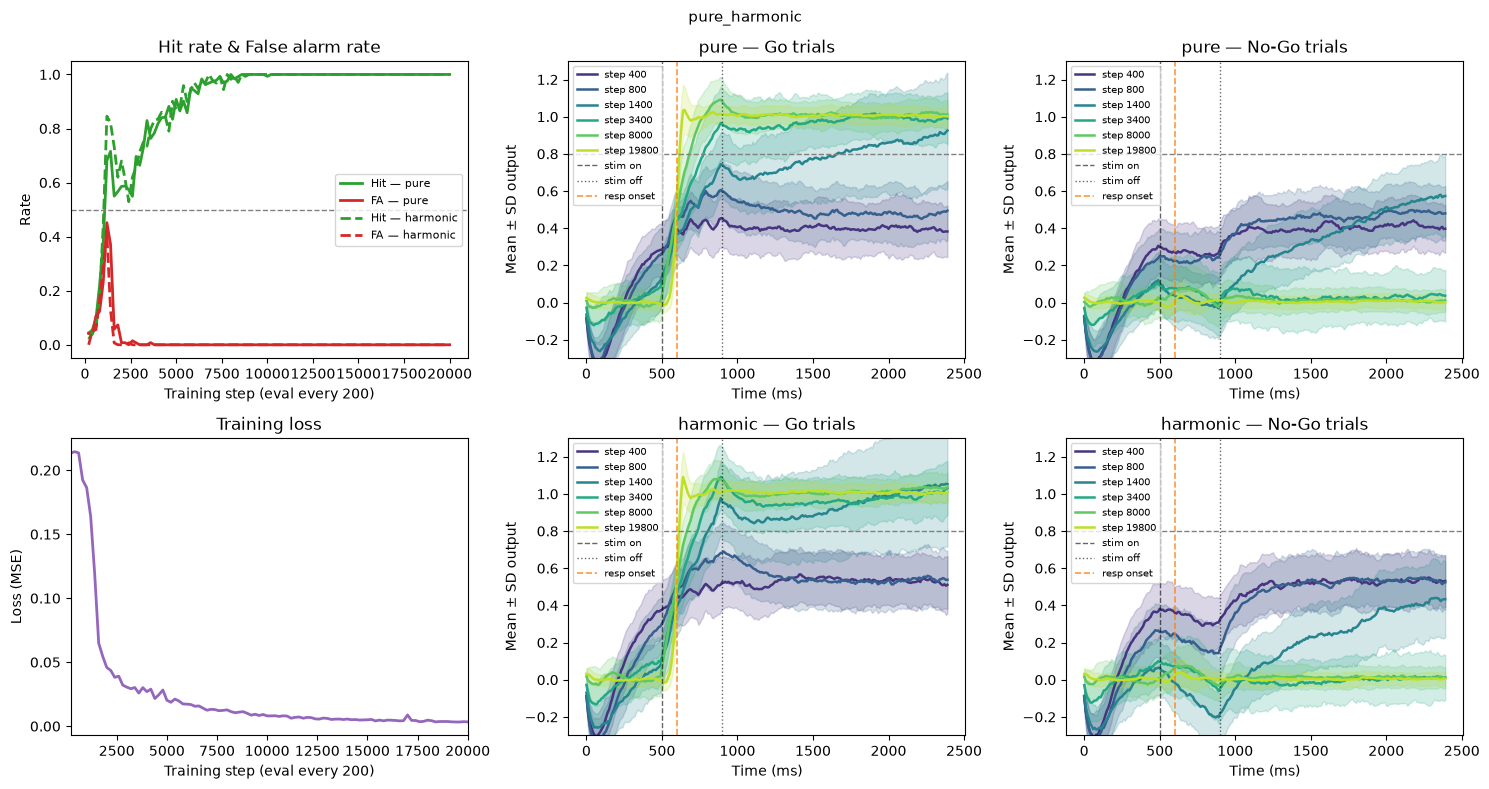

In [15]:
fig = plot_training_log(log, cfg, title='_'.join(train_tasks), last_snap_step=n_steps)

In [16]:
train_tasks

['pure', 'harmonic']